# Lab 1 — Credit Scoring : prédire la solvabilité d'un demandeur de crédit

**Formation Machine Learning pour le secteur bancaire** · Lab Classification (corrigé commenté)

| | |
|---|---|
| **Problème métier** | Une banque reçoit des demandes de crédit à la consommation. Elle veut estimer, pour chaque demande, la **probabilité de défaut** (PD) afin d'accepter, revoir ou refuser. |
| **Type de problème** | Apprentissage **supervisé** — **classification binaire** (`default` = 1 : mauvais payeur, 0 : bon payeur) |
| **Données** | *German Credit* (UCI) — 1 000 demandes, 20 variables (7 numériques, 13 catégorielles) |
| **Modèles** | Régression logistique · KNN · Arbre de décision · Random Forest · XGBoost |

### Déroulé du lab
1. Cadrage métier & chargement des données
2. Analyse exploratoire (EDA)
3. Preprocessing (pipeline, encodage, scaling, *data leakage*)
4. Feature engineering
5. Modèles de référence (baseline) en validation croisée
6. Sélection de variables (filtre, wrapper, embarquée, permutation)
7. Overfitting / underfitting : diagnostiquer et corriger
8. Fine-tuning des hyperparamètres
9. Évaluation finale : métriques, seuil optimisé par le coût, grille de risque
10. Équité & explicabilité
11. Vers la production : export, API, monitoring (PSI)

In [1]:
import time
import warnings

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns

from sklearn.compose import ColumnTransformer, make_column_selector
from sklearn.ensemble import RandomForestClassifier
from sklearn.feature_selection import RFECV, SelectKBest, mutual_info_classif
from sklearn.inspection import permutation_importance
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (ConfusionMatrixDisplay, classification_report, confusion_matrix,
                             precision_recall_curve, average_precision_score, roc_auc_score, roc_curve)
from sklearn.model_selection import (GridSearchCV, RandomizedSearchCV, StratifiedKFold, cross_val_predict,
                                     cross_val_score, cross_validate, learning_curve, train_test_split,
                                     validation_curve)
from sklearn.neighbors import KNeighborsClassifier
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import FunctionTransformer, OneHotEncoder, StandardScaler
from sklearn.tree import DecisionTreeClassifier, plot_tree
from xgboost import XGBClassifier

warnings.filterwarnings("ignore")
pd.set_option("display.max_columns", 50)
pd.set_option("display.float_format", "{:.3f}".format)
sns.set_theme(style="whitegrid", palette="deep")
plt.rcParams["figure.dpi"] = 100

RANDOM_STATE = 42
DATA_PATH = "data/german_credit.csv"

---
## 1. Cadrage métier & chargement des données

Avant toute ligne de code, on fixe **ce que l'on optimise**. En crédit, les deux erreurs n'ont pas le même coût :

| | Prédit *bon payeur* (accepté) | Prédit *mauvais payeur* (refusé) |
|---|---|---|
| **Réellement bon payeur** | ✅ 0 | ❌ **1** — marge perdue (faux positif) |
| **Réellement mauvais payeur** | ❌ **5** — perte en capital (faux négatif) | ✅ 0 |

> Matrice de coût officielle fournie avec le jeu de données (UCI) : **accepter un mauvais payeur coûte 5 fois plus cher que refuser un bon payeur**.
> Conséquence : l'*accuracy* n'est pas la bonne métrique. On suivra l'**AUC / Gini** (pouvoir discriminant), le **rappel** sur les défauts et le **coût métier**.

In [2]:
df = pd.read_csv(DATA_PATH)
print(f"Dimensions : {df.shape[0]} demandes × {df.shape[1]} colonnes")
df.head()

Dimensions : 1000 demandes × 21 colonnes


,checking_status,duration,credit_history,purpose,credit_amount,savings_status,employment,installment_commitment,personal_status,other_parties,residence_since,property_magnitude,age,other_payment_plans,housing,existing_credits,job,num_dependents,own_telephone,foreign_worker,default
0,<0,6,critical/other existing credit,radio/tv,1169,no known savings,>=7,4,male single,none,4,real estate,67,none,own,2,skilled,1,yes,yes,0
1,0<=X<200,48,existing paid,radio/tv,5951,<100,1<=X<4,2,female div/dep/mar,none,2,real estate,22,none,own,1,skilled,1,none,yes,1
2,no checking,12,critical/other existing credit,education,2096,<100,4<=X<7,2,male single,none,3,real estate,49,none,own,1,unskilled resident,2,none,yes,0
3,<0,42,existing paid,furniture/equipment,7882,<100,4<=X<7,2,male single,guarantor,4,life insurance,45,none,for free,1,skilled,2,none,yes,0
4,<0,24,delayed previously,new car,4870,<100,1<=X<4,3,male single,none,4,no known property,53,none,for free,2,skilled,2,none,yes,1


### Dictionnaire des variables

| Variable | Description | Variable | Description |
|---|---|---|---|
| `checking_status` | Solde du compte courant (DM) | `property_magnitude` | Patrimoine principal |
| `duration` | Durée du crédit (mois) | `age` | Âge (années) |
| `credit_history` | Historique de crédit | `other_payment_plans` | Autres crédits en cours (banque, magasin) |
| `purpose` | Objet du crédit | `housing` | Logement (propriétaire, locataire, gratuit) |
| `credit_amount` | Montant demandé (DM) | `existing_credits` | Nb de crédits dans la banque |
| `savings_status` | Épargne (DM) | `job` | Catégorie d'emploi |
| `employment` | Ancienneté dans l'emploi (années) | `num_dependents` | Personnes à charge |
| `installment_commitment` | Taux d'effort (mensualité / revenu, échelle 1–4) | `own_telephone` | Téléphone à son nom |
| `personal_status` | Sexe & statut marital | `foreign_worker` | Travailleur étranger |
| `other_parties` | Co-emprunteur / garant | **`default`** | **Cible : 1 = défaut, 0 = bon payeur** |
| `residence_since` | Ancienneté de résidence (années) | | |

In [3]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1000 entries, 0 to 999
Data columns (total 21 columns):
 #   Column                  Non-Null Count  Dtype 
---  ------                  --------------  ----- 
 0   checking_status         1000 non-null   object
 1   duration                1000 non-null   int64 
 2   credit_history          1000 non-null   object
 3   purpose                 1000 non-null   object
 4   credit_amount           1000 non-null   int64 
 5   savings_status          1000 non-null   object
 6   employment              1000 non-null   object
 7   installment_commitment  1000 non-null   int64 
 8   personal_status         1000 non-null   object
 9   other_parties           1000 non-null   object
 10  residence_since         1000 non-null   int64 
 11  property_magnitude      1000 non-null   object
 12  age                     1000 non-null   int64 
 13  other_payment_plans     1000 non-null   object
 14  housing                 1000 non-null   object
 15  exist

---
## 2. Analyse exploratoire (EDA)

Objectifs : comprendre la **cible**, la **qualité** des données, et repérer les variables **discriminantes** (qui séparent bons et mauvais payeurs).

### 2.1 La variable cible

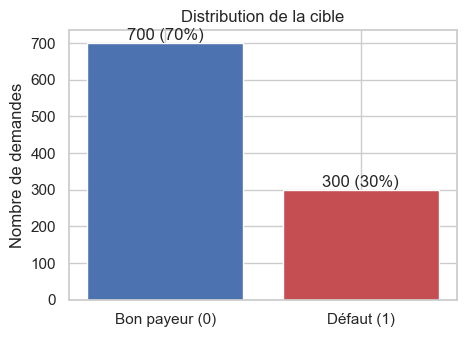

In [4]:
counts = df["default"].value_counts().sort_index()
fig, ax = plt.subplots(figsize=(5, 3.5))
bars = ax.bar(["Bon payeur (0)", "Défaut (1)"], counts.values, color=["#4C72B0", "#C44E52"])
ax.bar_label(bars, labels=[f"{v} ({v / len(df):.0%})" for v in counts.values])
ax.set_title("Distribution de la cible")
ax.set_ylabel("Nombre de demandes")
plt.show()

> **Déséquilibre modéré (70 / 30).** Un modèle « naïf » qui accepte tout le monde a 70 % d'accuracy… et ne détecte **aucun** défaut. C'est le *paradoxe de l'accuracy*.

### 2.2 Variables numériques

In [5]:
num_cols = df.select_dtypes("number").columns.drop("default").tolist()
cat_cols = df.select_dtypes("object").columns.tolist()
print("Numériques :", num_cols)
print("Catégorielles :", cat_cols)
df[num_cols].describe().T

Numériques : ['duration', 'credit_amount', 'installment_commitment', 'residence_since', 'age', 'existing_credits', 'num_dependents']
Catégorielles : ['checking_status', 'credit_history', 'purpose', 'savings_status', 'employment', 'personal_status', 'other_parties', 'property_magnitude', 'other_payment_plans', 'housing', 'job', 'own_telephone', 'foreign_worker']


,count,mean,std,min,25%,50%,75%,max
duration,1000.000,20.903,12.059,4.000,12.000,18.000,24.000,72.000
credit_amount,1000.000,3271.258,2822.737,250.000,1365.500,2319.500,3972.250,18424.000
installment_commitment,1000.000,2.973,1.119,1.000,2.000,3.000,4.000,4.000
residence_since,1000.000,2.845,1.104,1.000,2.000,3.000,4.000,4.000
age,1000.000,35.546,11.375,19.000,27.000,33.000,42.000,75.000
existing_credits,1000.000,1.407,0.578,1.000,1.000,1.000,2.000,4.000
num_dependents,1000.000,1.155,0.362,1.000,1.000,1.000,1.000,2.000


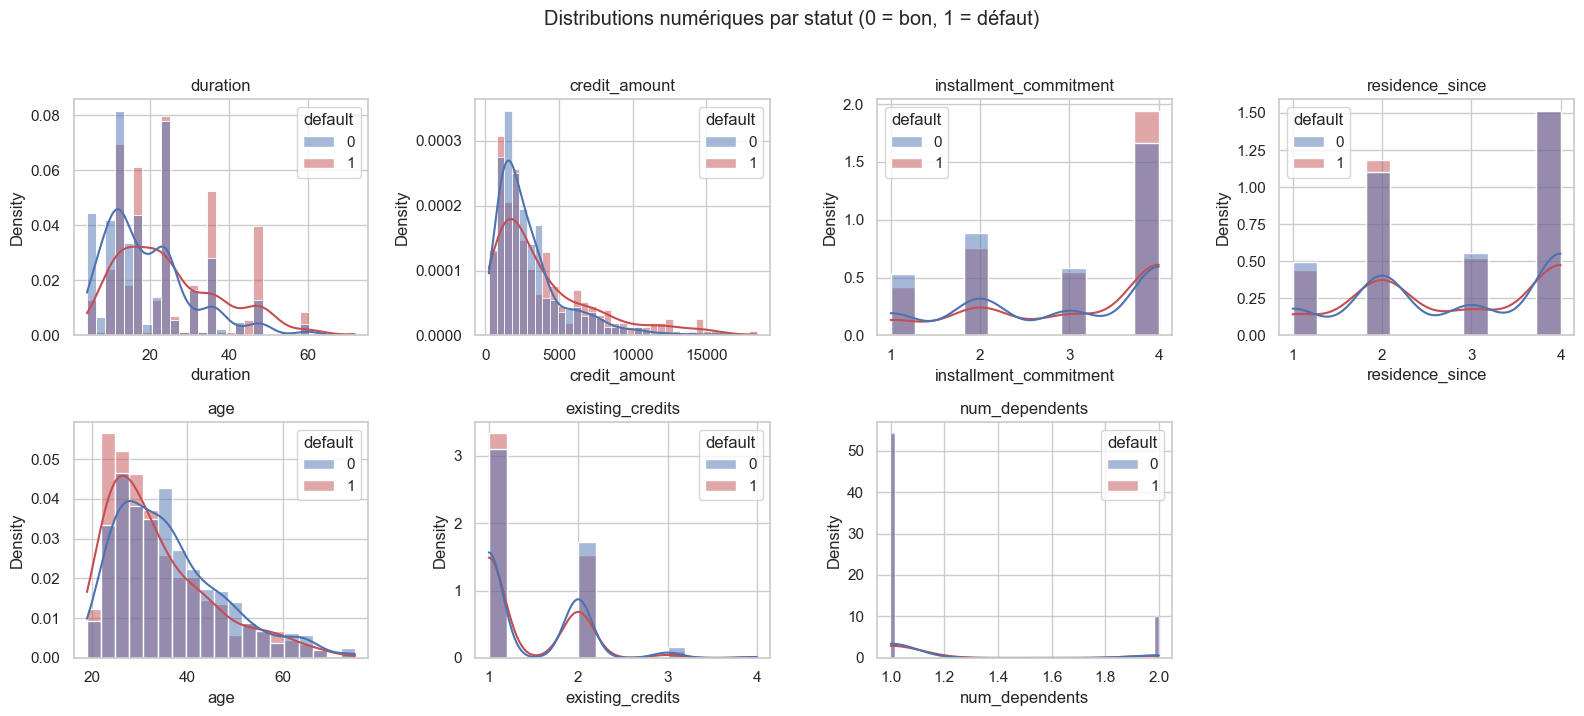

In [6]:
fig, axes = plt.subplots(2, 4, figsize=(16, 7))
for ax, col in zip(axes.flat, num_cols):
    sns.histplot(data=df, x=col, hue="default", kde=True, stat="density", common_norm=False,
                 palette={0: "#4C72B0", 1: "#C44E52"}, ax=ax)
    ax.set_title(col)
axes.flat[-1].axis("off")
plt.suptitle("Distributions numériques par statut (0 = bon, 1 = défaut)", y=1.02)
plt.tight_layout()
plt.show()

**Lecture :** les crédits **longs** (`duration`) et de **montant élevé** sont plus risqués ; les **jeunes** emprunteurs sont légèrement plus risqués. `credit_amount` est très **asymétrique** (queue à droite) → candidat à une transformation log.

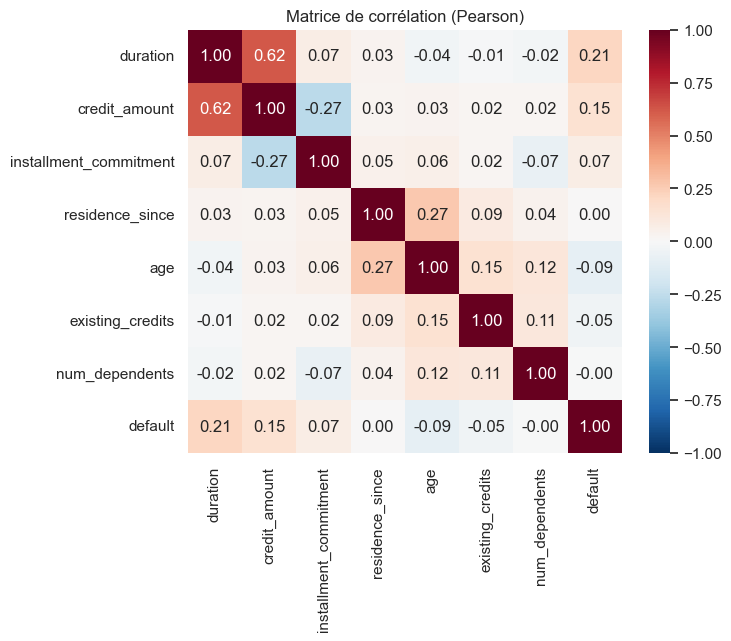

In [7]:
corr = df[num_cols + ["default"]].corr()
plt.figure(figsize=(7, 5.5))
sns.heatmap(corr, annot=True, fmt=".2f", cmap="RdBu_r", center=0, vmin=-1, vmax=1)
plt.title("Matrice de corrélation (Pearson)")
plt.show()

**Lecture :** `duration` et `credit_amount` sont corrélées (≈ 0,62) — logique, un gros crédit se rembourse sur plus longtemps. Aucune variable numérique n'est très corrélée seule à la cible : **c'est la combinaison** des variables qui fera la performance.

### 2.3 Variables catégorielles : taux de défaut par modalité

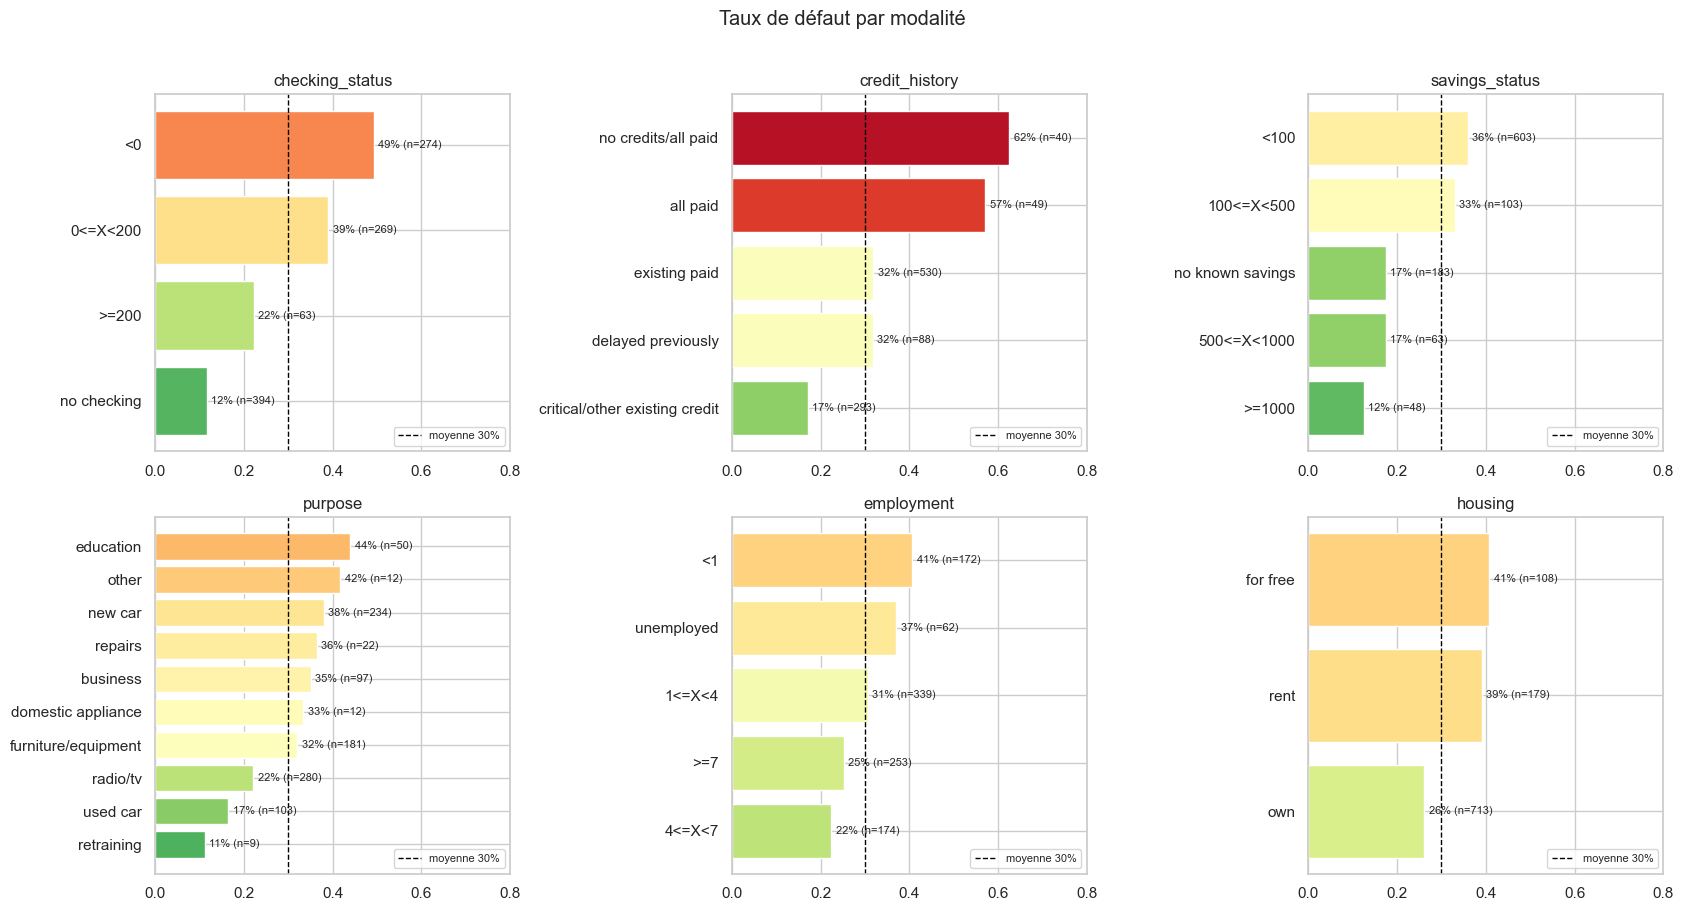

In [8]:
key_cats = ["checking_status", "credit_history", "savings_status", "purpose", "employment", "housing"]
global_rate = df["default"].mean()

fig, axes = plt.subplots(2, 3, figsize=(17, 9))
for ax, col in zip(axes.flat, key_cats):
    rates = df.groupby(col)["default"].agg(["mean", "size"]).sort_values("mean")
    ax.barh(rates.index, rates["mean"], color=plt.cm.RdYlGn_r(rates["mean"] / 0.65))
    ax.axvline(global_rate, color="black", ls="--", lw=1, label=f"moyenne {global_rate:.0%}")
    for i, (m, n) in enumerate(zip(rates["mean"], rates["size"])):
        ax.text(m + 0.01, i, f"{m:.0%} (n={n})", va="center", fontsize=8)
    ax.set_title(col)
    ax.set_xlim(0, 0.8)
    ax.legend(loc="lower right", fontsize=8)
plt.suptitle("Taux de défaut par modalité", y=1.01)
plt.tight_layout()
plt.show()

**À retenir (lecture métier) :**
- `checking_status` est la variable la plus discriminante : **49 %** de défaut pour un compte courant débiteur (`<0`) contre **12 %** sans compte courant dans la banque.
- Une **épargne faible** (`<100`) et une **faible ancienneté dans l'emploi** (`<1` an) augmentent le risque.
- Les **locataires** et les personnes **logées gratuitement** font plus défaut que les propriétaires.
- ⚠️ `credit_history = critical/other existing credit` affiche le taux le **plus bas** (17 %) : contre-intuitif ! Ces clients ont d'autres crédits **ailleurs** et sont donc déjà « filtrés » par d'autres banques. **Toujours confronter les données à l'expertise métier.**
- Certaines modalités sont **rares** (`purpose = retraining`, n = 9) → leurs taux sont peu fiables ; on les regroupera.

---
## 3. Preprocessing

### 3.1 Qualité des données : valeurs manquantes & outliers

Valeurs manquantes : 0
Doublons : 0


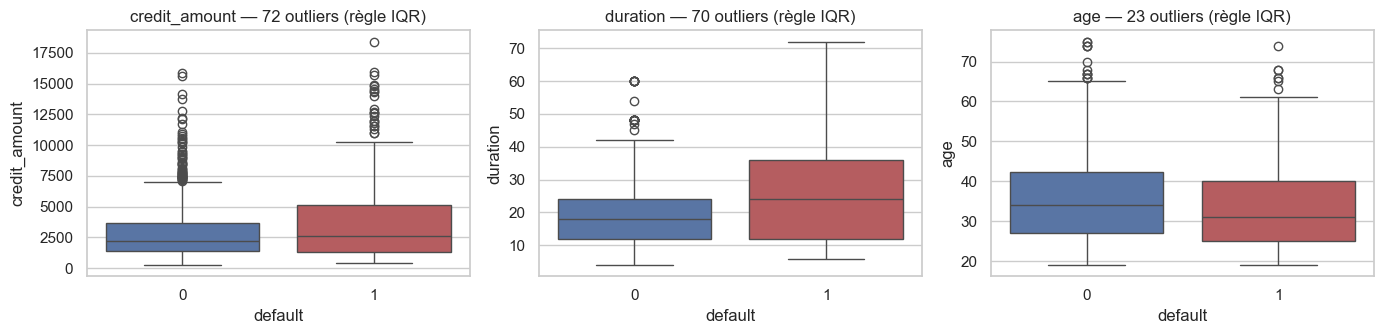

In [9]:
print("Valeurs manquantes :", int(df.isna().sum().sum()))
print("Doublons :", int(df.duplicated().sum()))

fig, axes = plt.subplots(1, 3, figsize=(14, 3.5))
for ax, col in zip(axes, ["credit_amount", "duration", "age"]):
    sns.boxplot(data=df, x="default", y=col, hue="default", ax=ax, palette=["#4C72B0", "#C44E52"], legend=False)
    q1, q3 = df[col].quantile([0.25, 0.75])
    n_out = ((df[col] < q1 - 1.5 * (q3 - q1)) | (df[col] > q3 + 1.5 * (q3 - q1))).sum()
    ax.set_title(f"{col} — {n_out} outliers (règle IQR)")
plt.tight_layout()
plt.show()

> Aucune valeur manquante. Les *outliers* (gros montants, longues durées) sont **réels et informatifs** en crédit : on ne les supprime pas. On atténuera l'asymétrie par une transformation log (feature engineering) et le **StandardScaler** limitera leur poids pour les modèles sensibles aux échelles (KNN, régression logistique).

### 3.2 Séparation train / test stratifiée

Le jeu de **test** (20 %) est mis de côté **et n'est plus touché** jusqu'à l'évaluation finale. `stratify=y` garantit le même taux de défaut (30 %) dans les deux jeux.

In [10]:
X = df.drop(columns="default")
y = df["default"]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, stratify=y, random_state=RANDOM_STATE)

print(f"Train : {X_train.shape}  — taux de défaut {y_train.mean():.1%}")
print(f"Test  : {X_test.shape}  — taux de défaut {y_test.mean():.1%}")

cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)

Train : (800, 20)  — taux de défaut 30.0%
Test  : (200, 20)  — taux de défaut 30.0%


### 3.3 Encodage et mise à l'échelle avec un `ColumnTransformer`

- **Numériques** → `StandardScaler` (moyenne 0, écart-type 1).
- **Catégorielles** → `OneHotEncoder` (une colonne binaire par modalité). `handle_unknown="ignore"` évite un plantage en production si une modalité inconnue arrive.

Les sélecteurs `make_column_selector` choisissent les colonnes **par type** : le même préprocesseur fonctionnera après ajout de nouvelles variables.

In [11]:
def make_preprocessor(min_frequency=None):
    return ColumnTransformer([
        ("num", StandardScaler(), make_column_selector(dtype_include="number")),
        ("cat", OneHotEncoder(handle_unknown="infrequent_if_exist" if min_frequency else "ignore",
                              min_frequency=min_frequency, sparse_output=False),
         make_column_selector(dtype_include="object")),
    ])

pre = make_preprocessor().fit(X_train)
X_train_enc = pre.transform(X_train)
print(f"{X_train.shape[1]} variables brutes  →  {X_train_enc.shape[1]} colonnes après encodage")
pd.DataFrame(X_train_enc[:3], columns=pre.get_feature_names_out()).iloc[:, :12]

20 variables brutes  →  61 colonnes après encodage


,num__duration,num__credit_amount,num__installment_commitment,num__residence_since,num__age,num__existing_credits,num__num_dependents,cat__checking_status_0<=X<200,cat__checking_status_<0,cat__checking_status_>=200,cat__checking_status_no checking,cat__credit_history_all paid
0,1.290,1.926,0.052,1.053,1.058,-0.719,-0.436,0.000,1.000,0.000,0.000,0.000
1,-0.743,-0.893,0.942,1.053,0.242,-0.719,-0.436,0.000,0.000,0.000,1.000,0.000
2,1.290,0.816,0.052,-0.747,-0.663,1.045,-0.436,0.000,1.000,0.000,0.000,0.000


### 3.4 Pourquoi un `Pipeline` ? Démonstration du *data leakage*

**Data leakage** = de l'information du jeu de validation « fuit » dans l'entraînement → scores **trop optimistes**, et déception en production.

Expérience : on génère des **données 100 % aléatoires** (aucun signal). On compare :
- ❌ sélection des 20 « meilleures » variables **sur tout le jeu**, *puis* validation croisée ;
- ✅ sélection **dans** un `Pipeline` : refaite à chaque pli uniquement sur les données d'entraînement.

In [12]:
rng = np.random.default_rng(RANDOM_STATE)
X_noise = rng.normal(size=(1000, 2000))      # 1000 clients, 2000 variables de bruit pur
y_noise = rng.integers(0, 2, size=1000)      # cible aléatoire

# ❌ Mauvaise pratique : sélection avant la validation croisée
X_sel = SelectKBest(k=20).fit_transform(X_noise, y_noise)
auc_leak = cross_val_score(LogisticRegression(max_iter=1000), X_sel, y_noise, cv=cv, scoring="roc_auc").mean()

# ✅ Bonne pratique : sélection dans le pipeline
pipe_ok = Pipeline([("select", SelectKBest(k=20)), ("model", LogisticRegression(max_iter=1000))])
auc_ok = cross_val_score(pipe_ok, X_noise, y_noise, cv=cv, scoring="roc_auc").mean()

print(f"AUC avec fuite de données : {auc_leak:.3f}   ← illusion de performance sur du bruit !")
print(f"AUC avec Pipeline        : {auc_ok:.3f}   ← ≈ 0,5 = hasard, la vérité")

AUC avec fuite de données : 0.692   ← illusion de performance sur du bruit !
AUC avec Pipeline        : 0.505   ← ≈ 0,5 = hasard, la vérité


> **Règle d'or :** toute opération qui « apprend » des données (scaling, imputation, encodage, sélection, rééchantillonnage) doit être **dans le pipeline**, ajustée sur le train uniquement. Le pipeline sera aussi l'**objet unique déployé** en production.

---
## 4. Feature engineering

Créer des variables **porteuses de sens métier**, souvent plus utiles qu'un modèle plus complexe :

| Nouvelle variable | Formule | Intuition métier |
|---|---|---|
| `monthly_payment` | `credit_amount / duration` | Mensualité approximative |
| `log_credit_amount` | `log(1 + credit_amount)` | Réduit l'asymétrie du montant |
| `employment_years` | ancienneté convertie en années | Variable ordinale → numérique |
| `amount_per_employment_year` | `credit_amount / (1 + employment_years)` | Montant rapporté à la stabilité professionnelle |
| `age_group` | tranches 18–25 / 26–35 / 36–50 / 50+ | Capture un effet non linéaire de l'âge |
| `has_checking_account` | `checking_status != "no checking"` | Client équipé d'un compte courant |

On regroupe aussi les **modalités rares** (< 2 % des demandes) via `OneHotEncoder(min_frequency=0.02)`.

In [13]:
EMPLOYMENT_YEARS = {"unemployed": 0, "<1": 0.5, "1<=X<4": 2.5, "4<=X<7": 5.5, ">=7": 10}

def add_features(data: pd.DataFrame) -> pd.DataFrame:
    d = data.copy()
    d["monthly_payment"] = d["credit_amount"] / d["duration"]
    d["log_credit_amount"] = np.log1p(d["credit_amount"])
    d["employment_years"] = d["employment"].map(EMPLOYMENT_YEARS).fillna(0)
    d["amount_per_employment_year"] = d["credit_amount"] / (1 + d["employment_years"])
    d["age_group"] = pd.cut(d["age"], bins=[0, 25, 35, 50, 120],
                            labels=["18-25", "26-35", "36-50", "50+"]).astype(str)
    d["has_checking_account"] = (d["checking_status"] != "no checking").astype(int)
    return d

fe = FunctionTransformer(add_features)
add_features(X_train).iloc[:3, -6:]

,monthly_payment,log_credit_amount,employment_years,amount_per_employment_year,age_group,has_checking_account
828,231.528,9.028,10.000,757.727,36-50,1
997,67.000,6.691,10.000,73.091,36-50,0
148,149.194,8.589,2.500,1534.571,26-35,1


In [14]:
def make_pipeline(model, feature_engineering=True):
    steps = [("fe", FunctionTransformer(add_features))] if feature_engineering else []
    steps += [("pre", make_preprocessor(min_frequency=0.02 if feature_engineering else None)),
              ("model", model)]
    return Pipeline(steps)

lr = LogisticRegression(max_iter=2000)
auc_raw = cross_val_score(make_pipeline(lr, False), X_train, y_train, cv=cv, scoring="roc_auc")
auc_fe = cross_val_score(make_pipeline(lr, True), X_train, y_train, cv=cv, scoring="roc_auc")
print(f"Régression logistique — AUC CV sans FE : {auc_raw.mean():.3f} ± {auc_raw.std():.3f}")
print(f"Régression logistique — AUC CV avec FE : {auc_fe.mean():.3f} ± {auc_fe.std():.3f}")

Régression logistique — AUC CV sans FE : 0.771 ± 0.053
Régression logistique — AUC CV avec FE : 0.768 ± 0.044


> **Résultat honnête : ici, pas de gain d'AUC** (l'écart est bien inférieur à l'écart-type de la CV). Les nouvelles variables sont en partie **redondantes** (la mensualité combine montant et durée, déjà présents). On les conserve car elles sont **neutres** en performance, réduisent un peu la variance entre plis et sont **plus parlantes** pour le métier (tranches d'âge, mensualité).
>
> **Leçon :** une variable « intelligente » doit être **validée**, pas présumée utile. Sur des données bancaires réelles (historiques de transactions, agrégats sur 3/6/12 mois, incidents de paiement, ratios d'endettement…), le feature engineering reste pourtant souvent **le premier levier de performance**.

---
## 5. Modèles de référence (baseline)

On compare les 5 algorithmes **avec leurs hyperparamètres par défaut**, en **validation croisée stratifiée à 5 plis** sur le train :

| Modèle | Idée en une phrase |
|---|---|
| **Régression logistique** | Combinaison linéaire des variables passée dans une sigmoïde → probabilité. Référence historique des *scorecards*. |
| **KNN** | Une demande ressemble à ses *k* plus proches voisins : on vote. |
| **Arbre de décision** | Suite de questions oui/non (« compte débiteur ? », « durée > 24 mois ? »). |
| **Random Forest** | Des centaines d'arbres entraînés sur des échantillons différents, qui votent (*bagging*). |
| **XGBoost** | Des arbres construits **séquentiellement**, chacun corrigeant les erreurs des précédents (*boosting*). |

`class_weight="balanced"` (ou `scale_pos_weight` pour XGBoost) donne plus de poids aux défauts, minoritaires.

In [15]:
pos_weight = (y_train == 0).sum() / (y_train == 1).sum()

baseline_models = {
    "Régression logistique": LogisticRegression(max_iter=2000, class_weight="balanced"),
    "KNN": KNeighborsClassifier(),
    "Arbre de décision": DecisionTreeClassifier(class_weight="balanced", random_state=RANDOM_STATE),
    "Random Forest": RandomForestClassifier(class_weight="balanced", random_state=RANDOM_STATE, n_jobs=-1),
    "XGBoost": XGBClassifier(scale_pos_weight=pos_weight, eval_metric="logloss",
                             random_state=RANDOM_STATE, n_jobs=-1),
}

scoring = {"AUC": "roc_auc", "F1": "f1", "Rappel": "recall", "Précision": "precision", "Accuracy": "accuracy"}
rows = []
for name, model in baseline_models.items():
    res = cross_validate(make_pipeline(model), X_train, y_train, cv=cv, scoring=scoring)
    row = {"Modèle": name}
    row.update({m: res[f"test_{m}"].mean() for m in scoring})
    row["Gini"] = 2 * row["AUC"] - 1
    row["Temps fit (s)"] = res["fit_time"].mean()
    rows.append(row)

baseline = pd.DataFrame(rows).set_index("Modèle").sort_values("AUC", ascending=False)
baseline[["AUC", "Gini", "F1", "Rappel", "Précision", "Accuracy", "Temps fit (s)"]]

,AUC,Gini,F1,Rappel,Précision,Accuracy,Temps fit (s)
Modèle,,,,,,,
Random Forest,0.794,0.587,0.477,0.362,0.709,0.766,0.067
XGBoost,0.778,0.556,0.574,0.558,0.593,0.752,0.180
Régression logistique,0.768,0.536,0.581,0.683,0.506,0.705,0.011
KNN,0.737,0.474,0.457,0.383,0.566,0.728,0.008
Arbre de décision,0.617,0.234,0.461,0.450,0.476,0.684,0.011


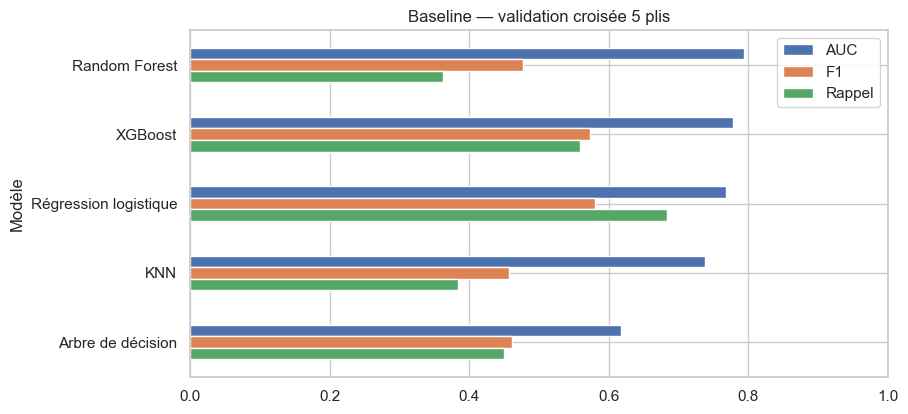

In [16]:
ax = baseline[["AUC", "F1", "Rappel"]].plot.barh(figsize=(9, 4.5), color=["#4C72B0", "#DD8452", "#55A868"])
ax.set_xlim(0, 1)
ax.set_title("Baseline — validation croisée 5 plis")
ax.invert_yaxis()
plt.show()

**Lecture :**
- Les **méthodes d'ensemble** (Random Forest, XGBoost) sont en tête en AUC, mais la **régression logistique**, bien plus simple, n'est qu'à quelques points — et elle a le **meilleur rappel** (grâce à `class_weight="balanced"`).
- À l'inverse, le Random Forest a une bonne AUC mais un **rappel faible au seuil 0,5** : AUC et métriques « à seuil » ne racontent pas la même histoire (cf. section 9).
- L'**arbre de décision** seul est le plus faible : sans contrainte de profondeur, il **apprend par cœur** le train (on le verra en section 7).
- Le **KNN** souffre du grand nombre de colonnes binaires (*malédiction de la dimension*).
- **Gini = 2 × AUC − 1** est l'indicateur de discrimination le plus utilisé en risque de crédit : un Gini de 0,5–0,6 est typique d'un score d'octroi.

---
## 6. Sélection de variables

Moins de variables = modèle **plus simple à expliquer**, à **documenter** (validation de modèle) et à **maintenir** en production (moins de flux de données). Trois familles :

| Famille | Principe | Exemple utilisé |
|---|---|---|
| **Filtre** | Score statistique variable par variable, indépendamment du modèle | Information mutuelle |
| **Wrapper** | On entraîne le modèle sur différents sous-ensembles | RFE (élimination récursive) |
| **Embarquée** | La sélection se fait pendant l'entraînement | Régularisation L1 (Lasso), importance des arbres |

### 6.1 Filtre : information mutuelle

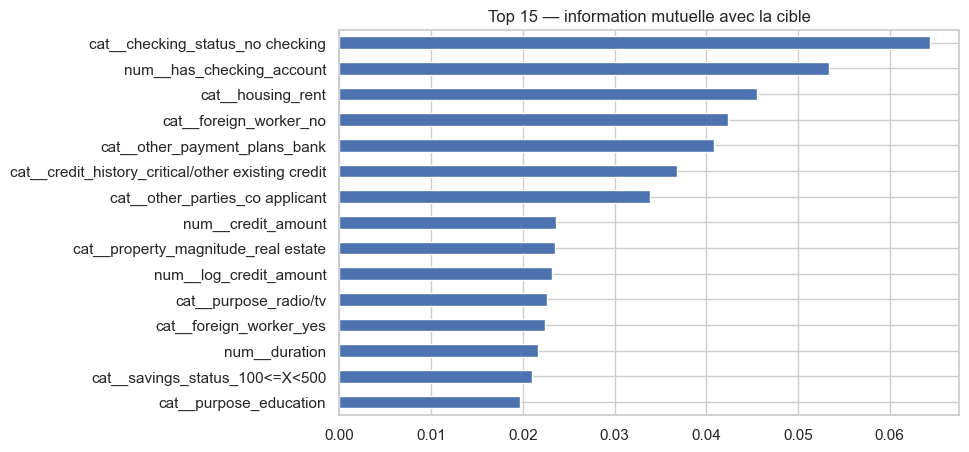

In [17]:
pre_fe = make_preprocessor(min_frequency=0.02)
X_tr_fe = pre_fe.fit_transform(add_features(X_train))
feat_names = pre_fe.get_feature_names_out()

mi = pd.Series(mutual_info_classif(X_tr_fe, y_train, random_state=RANDOM_STATE), index=feat_names)
mi.sort_values().tail(15).plot.barh(figsize=(8, 5), color="#4C72B0")
plt.title("Top 15 — information mutuelle avec la cible")
plt.show()

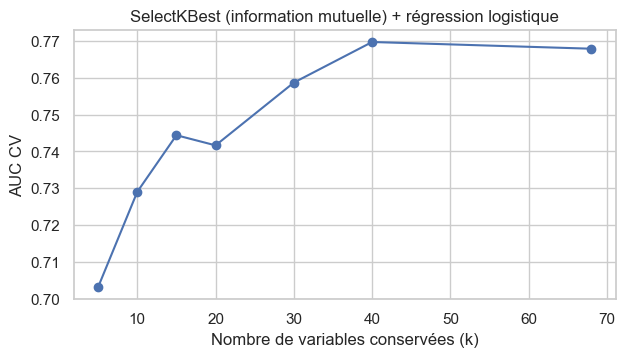

{5: np.float64(0.703), 10: np.float64(0.729), 15: np.float64(0.744), 20: np.float64(0.742), 30: np.float64(0.759), 40: np.float64(0.77), 68: np.float64(0.768)}


In [18]:
ks = [5, 10, 15, 20, 30, 40, X_tr_fe.shape[1]]
scores_k = []
for k in ks:
    pipe = Pipeline([("fe", FunctionTransformer(add_features)), ("pre", make_preprocessor(0.02)),
                     ("select", SelectKBest(lambda X, y: mutual_info_classif(X, y, random_state=RANDOM_STATE), k=k)),
                     ("model", LogisticRegression(max_iter=2000, class_weight="balanced"))])
    scores_k.append(cross_val_score(pipe, X_train, y_train, cv=cv, scoring="roc_auc").mean())

plt.figure(figsize=(7, 3.5))
plt.plot(ks, scores_k, marker="o")
plt.xlabel("Nombre de variables conservées (k)")
plt.ylabel("AUC CV")
plt.title("SelectKBest (information mutuelle) + régression logistique")
plt.show()
print(dict(zip(ks, np.round(scores_k, 3))))

### 6.2 Wrapper : élimination récursive (RFECV)

On retire itérativement la variable la moins utile au modèle, et la validation croisée indique le **nombre optimal** de variables.

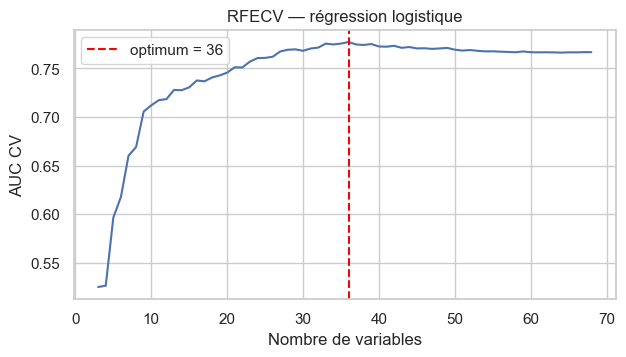

AUC CV optimale : 0.777 avec 36 colonnes / 68
Variables retenues : ['num__duration', 'num__credit_amount', 'num__installment_commitment', 'num__has_checking_account', 'cat__checking_status_<0', 'cat__checking_status_no checking', 'cat__credit_history_all paid', 'cat__credit_history_critical/other existing credit', 'cat__credit_history_no credits/all paid', 'cat__purpose_education', 'cat__purpose_new car', 'cat__purpose_radio/tv', 'cat__purpose_repairs', 'cat__purpose_used car', 'cat__purpose_infrequent_sklearn', 'cat__savings_status_<100', 'cat__savings_status_>=1000', 'cat__savings_status_no known savings', 'cat__employment_4<=X<7', 'cat__employment_<1', 'cat__employment_unemployed', 'cat__personal_status_male div/sep', 'cat__personal_status_male single', 'cat__other_parties_co applicant', 'cat__other_parties_guarantor', 'cat__property_magnitude_no known property', 'cat__property_magnitude_real estate', 'cat__other_payment_plans_bank', 'cat__other_payment_plans_none', 'cat__housing_fo

In [19]:
rfecv = RFECV(LogisticRegression(max_iter=2000, class_weight="balanced"), step=1, cv=cv,
              scoring="roc_auc", min_features_to_select=3, n_jobs=-1)
rfecv.fit(X_tr_fe, y_train)

n_feats = np.arange(rfecv.min_features_to_select, X_tr_fe.shape[1] + 1)
plt.figure(figsize=(7, 3.5))
plt.plot(n_feats, rfecv.cv_results_["mean_test_score"])
plt.axvline(rfecv.n_features_, color="red", ls="--", label=f"optimum = {rfecv.n_features_}")
plt.xlabel("Nombre de variables")
plt.ylabel("AUC CV")
plt.title("RFECV — régression logistique")
plt.legend()
plt.show()
print(f"AUC CV optimale : {rfecv.cv_results_['mean_test_score'].max():.3f} avec {rfecv.n_features_} colonnes / {X_tr_fe.shape[1]}")
print("Variables retenues :", list(feat_names[rfecv.support_]))

### 6.3 Embarquée : régularisation L1 (Lasso)

La pénalité L1 pousse les coefficients inutiles **exactement à zéro** : la sélection est intégrée à l'entraînement. Plus `C` est petit, plus la régularisation est forte.

In [20]:
for C in [0.01, 0.05, 0.1, 0.5, 1.0]:
    l1 = LogisticRegression(penalty="l1", solver="liblinear", C=C, class_weight="balanced", max_iter=2000)
    auc = cross_val_score(make_pipeline(l1), X_train, y_train, cv=cv, scoring="roc_auc").mean()
    n_nonzero = (make_pipeline(l1).fit(X_train, y_train)["model"].coef_ != 0).sum()
    print(f"C = {C:<5} → {n_nonzero:>2} variables non nulles / {X_tr_fe.shape[1]}  — AUC CV = {auc:.3f}")

C = 0.01  →  1 variables non nulles / 68  — AUC CV = 0.669
C = 0.05  → 10 variables non nulles / 68  — AUC CV = 0.745


C = 0.1   → 22 variables non nulles / 68  — AUC CV = 0.760


C = 0.5   → 39 variables non nulles / 68  — AUC CV = 0.771
C = 1.0   → 51 variables non nulles / 68  — AUC CV = 0.766


### 6.4 Importance par permutation (agnostique du modèle)

On **mélange** une variable sur le jeu de validation et on mesure la **chute d'AUC** : si le modèle s'en sert, la performance chute. Avantage : fonctionne pour **n'importe quel modèle**, directement sur les **variables brutes** (lisible par le métier).

> On l'évalue ici sur un **pli de validation** extrait du train : le jeu de test reste intact.

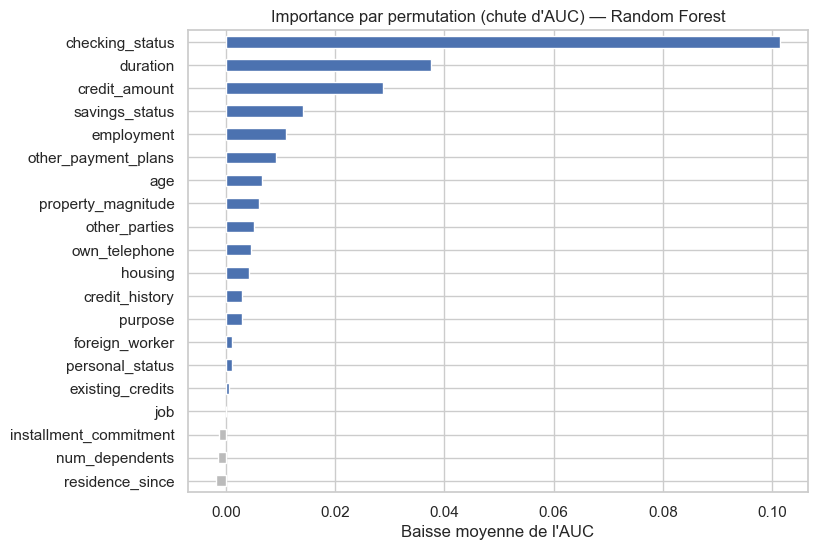

In [21]:
X_fit, X_val, y_fit, y_val = train_test_split(X_train, y_train, test_size=0.25, stratify=y_train,
                                              random_state=RANDOM_STATE)
rf_pipe = make_pipeline(RandomForestClassifier(n_estimators=300, class_weight="balanced",
                                               min_samples_leaf=3, random_state=RANDOM_STATE, n_jobs=-1))
rf_pipe.fit(X_fit, y_fit)
perm = permutation_importance(rf_pipe, X_val, y_val, scoring="roc_auc", n_repeats=15,
                              random_state=RANDOM_STATE, n_jobs=-1)
perm_imp = pd.Series(perm.importances_mean, index=X_val.columns).sort_values()
perm_imp.plot.barh(figsize=(8, 6), color=np.where(perm_imp > 0, "#4C72B0", "#BBBBBB"))
plt.title("Importance par permutation (chute d'AUC) — Random Forest")
plt.xlabel("Baisse moyenne de l'AUC")
plt.show()

**Synthèse :** un **noyau commun** ressort de toutes les méthodes : **`checking_status`** (de loin), **`duration`**, **`credit_amount`**, **`savings_status`** ; viennent ensuite, selon la méthode, `employment`, `credit_history`, `purpose`, `other_payment_plans`. Les variables à importance ≈ 0 ou négative (`residence_since`, `num_dependents`, `installment_commitment` pour le Random Forest) sont candidates à la suppression.

> Sur ce petit jeu, la sélection ne **gagne** pas d'AUC, mais on peut **retirer une bonne partie des colonnes** pour une perte faible (RFECV, ou L1 avec `C = 0,1` : environ un tiers des colonnes pour moins d'un point d'AUC). En banque, c'est souvent l'argument décisif : parcimonie, documentation du modèle, coût et risque des flux de données.

---
## 7. Overfitting & underfitting

| | Underfitting (sous-apprentissage) | Bon compromis | Overfitting (sur-apprentissage) |
|---|---|---|---|
| Score train | faible | élevé | **très élevé** (≈ parfait) |
| Score validation | faible | élevé | **nettement plus bas** |
| Cause | modèle trop simple | — | modèle trop complexe, il apprend le bruit |
| Remède | plus de variables, modèle plus riche | — | régularisation, élagage, plus de données, CV |

### 7.1 L'arbre qui apprend par cœur

In [22]:
for depth in [None, 4]:
    tree = make_pipeline(DecisionTreeClassifier(max_depth=depth, class_weight="balanced",
                                                random_state=RANDOM_STATE)).fit(X_fit, y_fit)
    auc_tr = roc_auc_score(y_fit, tree.predict_proba(X_fit)[:, 1])
    auc_va = roc_auc_score(y_val, tree.predict_proba(X_val)[:, 1])
    print(f"max_depth = {str(depth):<4}  AUC train = {auc_tr:.3f} | AUC validation = {auc_va:.3f} "
          f"| écart = {auc_tr - auc_va:.3f}  (profondeur réelle : {tree['model'].get_depth()})")

max_depth = None  AUC train = 1.000 | AUC validation = 0.644 | écart = 0.356  (profondeur réelle : 13)
max_depth = 4     AUC train = 0.843 | AUC validation = 0.674 | écart = 0.168  (profondeur réelle : 4)


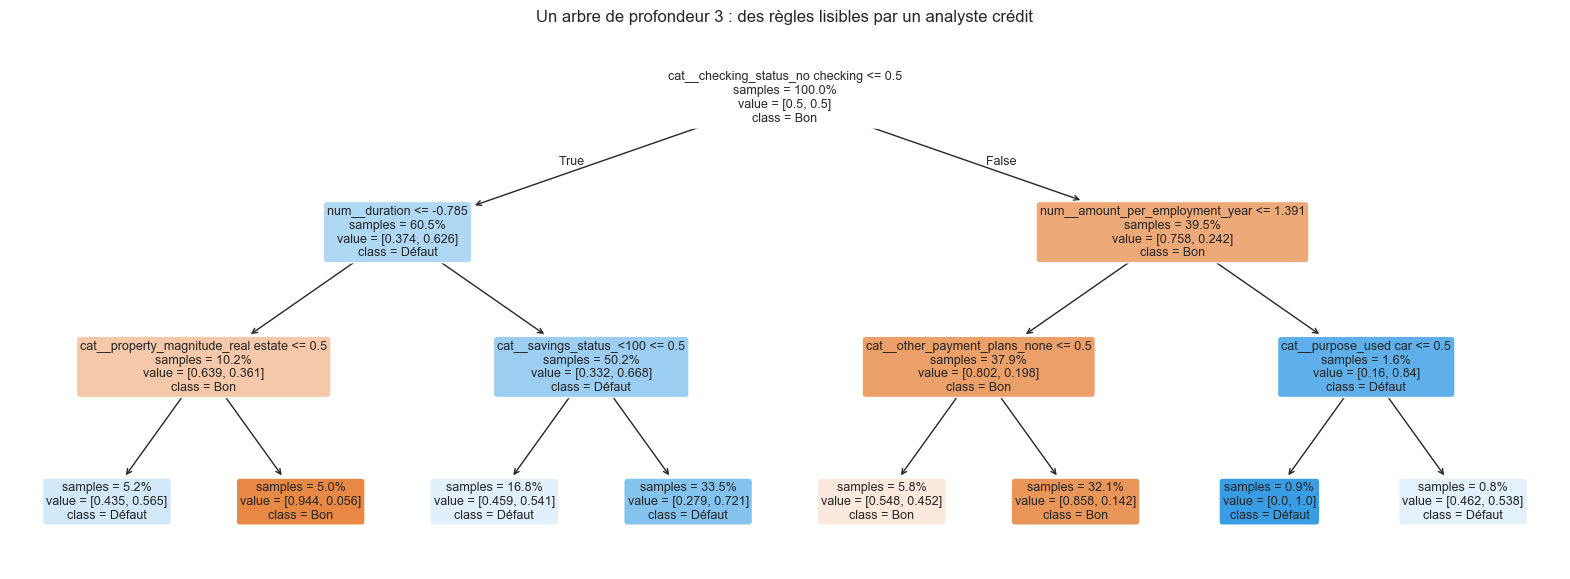

In [23]:
small_tree = make_pipeline(DecisionTreeClassifier(max_depth=3, class_weight="balanced",
                                                  random_state=RANDOM_STATE)).fit(X_train, y_train)
plt.figure(figsize=(20, 7))
plot_tree(small_tree["model"], feature_names=small_tree["pre"].get_feature_names_out(),
          class_names=["Bon", "Défaut"], filled=True, rounded=True, fontsize=9, impurity=False, proportion=True)
plt.title("Un arbre de profondeur 3 : des règles lisibles par un analyste crédit")
plt.show()

### 7.2 Courbes de validation : trouver la bonne complexité

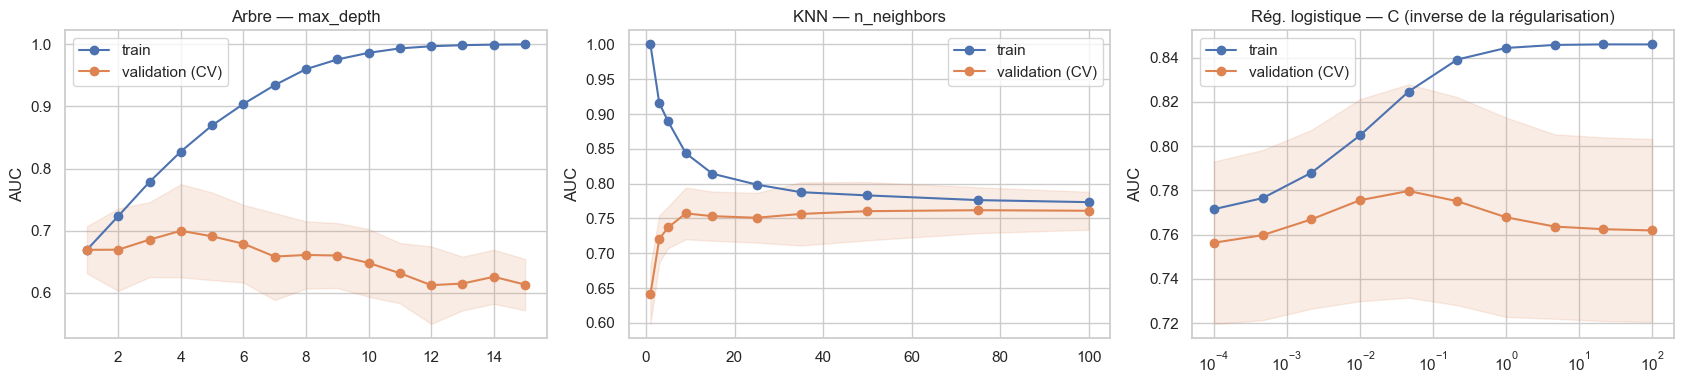

In [24]:
fig, axes = plt.subplots(1, 3, figsize=(17, 4))
curves = [
    ("Arbre — max_depth", make_pipeline(DecisionTreeClassifier(class_weight="balanced", random_state=RANDOM_STATE)),
     "model__max_depth", np.arange(1, 16), False),
    ("KNN — n_neighbors", make_pipeline(KNeighborsClassifier()), "model__n_neighbors",
     np.array([1, 3, 5, 9, 15, 25, 35, 50, 75, 100]), False),
    ("Rég. logistique — C (inverse de la régularisation)", make_pipeline(LogisticRegression(max_iter=3000, class_weight="balanced")),
     "model__C", np.logspace(-4, 2, 10), True),
]
for ax, (title, pipe, param, values, logx) in zip(axes, curves):
    tr, va = validation_curve(pipe, X_train, y_train, param_name=param, param_range=values,
                              cv=cv, scoring="roc_auc", n_jobs=-1)
    ax.plot(values, tr.mean(1), marker="o", label="train")
    ax.plot(values, va.mean(1), marker="o", label="validation (CV)")
    ax.fill_between(values, va.mean(1) - va.std(1), va.mean(1) + va.std(1), alpha=0.15, color="C1")
    if logx:
        ax.set_xscale("log")
    ax.set_title(title)
    ax.set_ylabel("AUC")
    ax.legend()
plt.tight_layout()
plt.show()

**Lecture :**
- **Arbre** : au-delà de 3–5 niveaux, l'AUC train continue de monter vers 1 alors que la validation **décroît** → overfitting.
- **KNN** : `k = 1` = overfitting extrême (chaque client est son propre voisin) ; `k` très grand = underfitting (on prédit la moyenne).
- **Régression logistique** : `C` très petit = trop régularisé (underfitting) ; l'optimum est autour de `C ≈ 0,03–0,05` ; au-delà, le train progresse encore mais la validation **baisse** : le modèle commence à sur-apprendre.

### 7.3 Courbe d'apprentissage : faut-il plus de données ?

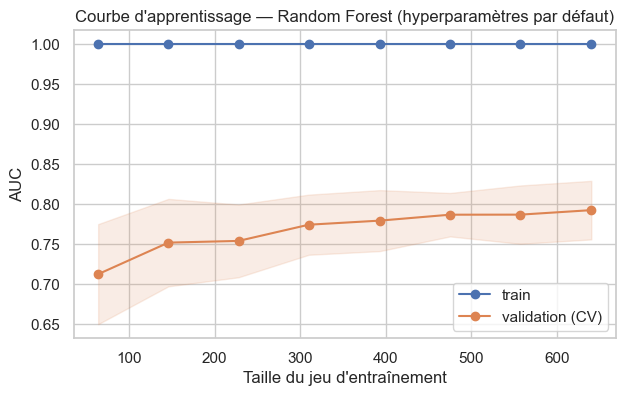

In [25]:
sizes, tr, va = learning_curve(make_pipeline(RandomForestClassifier(n_estimators=200, class_weight="balanced",
                                                                    random_state=RANDOM_STATE, n_jobs=-1)),
                               X_train, y_train, cv=cv, scoring="roc_auc",
                               train_sizes=np.linspace(0.1, 1.0, 8), n_jobs=-1)
plt.figure(figsize=(7, 4))
plt.plot(sizes, tr.mean(1), marker="o", label="train")
plt.plot(sizes, va.mean(1), marker="o", label="validation (CV)")
plt.fill_between(sizes, va.mean(1) - va.std(1), va.mean(1) + va.std(1), alpha=0.15, color="C1")
plt.xlabel("Taille du jeu d'entraînement")
plt.ylabel("AUC")
plt.title("Courbe d'apprentissage — Random Forest (hyperparamètres par défaut)")
plt.legend()
plt.show()

> Écart train/validation important et courbe de validation **encore croissante** → le modèle bénéficierait de **plus de données** (et/ou d'une régularisation plus forte, par ex. `min_samples_leaf`). Avec 800 demandes, nous sommes dans un régime « petites données ».

---
## 8. Fine-tuning des hyperparamètres

- **Paramètres** : appris par le modèle (coefficients, seuils des arbres).
- **Hyperparamètres** : choisis **avant** l'entraînement (profondeur, nombre d'arbres, `C`, `k`…).

| Méthode | Principe | Quand l'utiliser |
|---|---|---|
| `GridSearchCV` | Teste **toutes** les combinaisons d'une grille | Peu d'hyperparamètres |
| `RandomizedSearchCV` | Tire **N combinaisons au hasard** | Espaces larges (RF, XGBoost) |
| Optimisation bayésienne (Optuna) | Choisit la prochaine combinaison selon les résultats précédents | Modèles coûteux |

Chaque combinaison est évaluée en **validation croisée 5 plis** sur le train, avec l'**AUC** comme critère.

In [26]:
search_spaces = {
    "Régression logistique": (GridSearchCV, LogisticRegression(max_iter=3000, solver="liblinear"), {
        "model__C": [0.005, 0.01, 0.03, 0.1, 0.3, 1, 3],
        "model__penalty": ["l1", "l2"],
        "model__class_weight": [None, "balanced"],
    }),
    "KNN": (GridSearchCV, KNeighborsClassifier(), {
        "model__n_neighbors": [5, 11, 15, 21, 31, 41, 51],
        "model__weights": ["uniform", "distance"],
        "model__p": [1, 2],
    }),
    "Arbre de décision": (GridSearchCV, DecisionTreeClassifier(random_state=RANDOM_STATE), {
        "model__max_depth": [2, 3, 4, 5, 6, 8],
        "model__min_samples_leaf": [1, 5, 10, 20, 40],
        "model__criterion": ["gini", "entropy"],
        "model__class_weight": [None, "balanced"],
    }),
    "Random Forest": (RandomizedSearchCV, RandomForestClassifier(random_state=RANDOM_STATE, n_jobs=-1), {
        "model__n_estimators": [200, 400, 600],
        "model__max_depth": [4, 6, 8, 12, None],
        "model__min_samples_leaf": [1, 3, 5, 10],
        "model__max_features": ["sqrt", 0.3, 0.5],
        "model__class_weight": [None, "balanced", "balanced_subsample"],
    }),
    "XGBoost": (RandomizedSearchCV, XGBClassifier(eval_metric="logloss", random_state=RANDOM_STATE, n_jobs=-1), {
        "model__n_estimators": [100, 200, 400, 600],
        "model__max_depth": [2, 3, 4, 5],
        "model__learning_rate": [0.01, 0.03, 0.05, 0.1],
        "model__subsample": [0.7, 0.85, 1.0],
        "model__colsample_bytree": [0.5, 0.7, 1.0],
        "model__min_child_weight": [1, 3, 5],
        "model__reg_lambda": [1, 5, 10],
        "model__scale_pos_weight": [1, pos_weight],
    }),
}

tuned, tuning_rows = {}, []
for name, (Search, model, grid) in search_spaces.items():
    t0 = time.time()
    kwargs = {"n_iter": 30, "random_state": RANDOM_STATE} if Search is RandomizedSearchCV else {}
    search = Search(make_pipeline(model), grid, cv=cv, scoring="roc_auc", n_jobs=-1, **kwargs)
    search.fit(X_train, y_train)
    tuned[name] = search
    tuning_rows.append({
        "Modèle": name,
        "AUC CV baseline": baseline.loc[name, "AUC"],
        "AUC CV optimisé": search.best_score_,
        "Gain": search.best_score_ - baseline.loc[name, "AUC"],
        "Durée (s)": time.time() - t0,
        "Meilleurs hyperparamètres": {k.replace("model__", ""): v for k, v in search.best_params_.items()},
    })

tuning = pd.DataFrame(tuning_rows).set_index("Modèle").sort_values("AUC CV optimisé", ascending=False)
with pd.option_context("display.max_colwidth", 200):
    display(tuning)

,AUC CV baseline,AUC CV optimisé,Gain,Durée (s),Meilleurs hyperparamètres
Modèle,,,,,
Random Forest,0.794,0.799,0.005,9.001,"{'n_estimators': 400, 'min_samples_leaf': 1, 'max_features': 'sqrt', 'max_depth': 12, 'class_weight': 'balanced_subsample'}"
XGBoost,0.778,0.793,0.015,1.054,"{'subsample': 0.85, 'scale_pos_weight': 1, 'reg_lambda': 1, 'n_estimators': 200, 'min_child_weight': 1, 'max_depth': 3, 'learning_rate': 0.03, 'colsample_bytree': 0.7}"
Régression logistique,0.768,0.779,0.011,0.220,"{'C': 0.03, 'class_weight': None, 'penalty': 'l2'}"
KNN,0.737,0.778,0.040,0.224,"{'n_neighbors': 31, 'p': 1, 'weights': 'distance'}"
Arbre de décision,0.617,0.734,0.117,0.799,"{'class_weight': None, 'criterion': 'gini', 'max_depth': 4, 'min_samples_leaf': 10}"


**Lecture :** le tuning apporte le plus aux modèles **sensibles à leur complexité** (arbre, KNN). Les modèles déjà robustes (régression logistique) gagnent peu. Une fois réglés, les meilleurs modèles sont **très proches** : l'écart se joue à quelques millièmes d'AUC, souvent **dans le bruit** de la validation croisée.

### Choix du modèle retenu

En banque, à performance comparable, on privilégie le modèle le plus **explicable** et le plus **stable** : un score d'octroi doit pouvoir justifier chaque refus au client et au régulateur.

Règle appliquée : *si l'écart d'AUC entre le meilleur modèle et la régression logistique est **inférieur à l'écart-type** des scores de validation croisée du meilleur modèle, l'écart n'est pas significatif → on retient la régression logistique.*

In [27]:
best_name = tuning["AUC CV optimisé"].idxmax()
best_search = tuned[best_name]
cv_std = best_search.cv_results_["std_test_score"][best_search.best_index_]
gap = tuning.loc[best_name, "AUC CV optimisé"] - tuning.loc["Régression logistique", "AUC CV optimisé"]
retained_name = "Régression logistique" if gap < cv_std else best_name
final_model = tuned[retained_name].best_estimator_

print(f"Meilleur modèle en CV : {best_name}  (AUC {best_search.best_score_:.3f} ± {cv_std:.3f})")
print(f"Écart avec la régression logistique : {gap:.3f}  →  {'non significatif' if gap < cv_std else 'significatif'}")
print(f"Modèle retenu          : {retained_name}")
print("Hyperparamètres       :", tuning.loc[retained_name, "Meilleurs hyperparamètres"])

Meilleur modèle en CV : Random Forest  (AUC 0.799 ± 0.035)
Écart avec la régression logistique : 0.020  →  non significatif
Modèle retenu          : Régression logistique
Hyperparamètres       : {'C': 0.03, 'class_weight': None, 'penalty': 'l2'}


---
## 9. Évaluation finale sur le jeu de test

Le jeu de test (200 demandes jamais vues) simule la **production**. On ne l'utilise qu'**une seule fois**, pour estimer la performance réelle.

### 9.1 Courbes ROC de tous les modèles optimisés

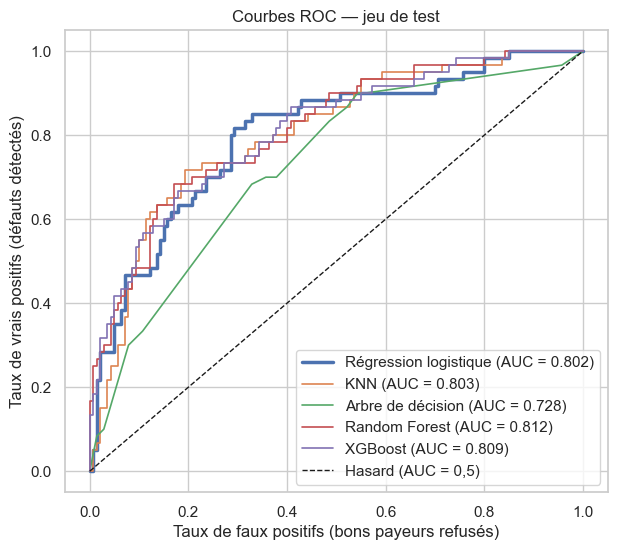

,AUC test,Gini test,KS test,AUC CV
Modèle,,,,
Random Forest,0.812,0.624,0.512,0.799
XGBoost,0.809,0.619,0.488,0.793
KNN,0.803,0.607,0.524,0.778
Régression logistique,0.802,0.603,0.524,0.779
Arbre de décision,0.728,0.456,0.357,0.734


In [28]:
test_rows = []
plt.figure(figsize=(7, 6))
for name, search in tuned.items():
    proba = search.predict_proba(X_test)[:, 1]
    fpr, tpr, _ = roc_curve(y_test, proba)
    auc = roc_auc_score(y_test, proba)
    test_rows.append({"Modèle": name, "AUC test": auc, "Gini test": 2 * auc - 1,
                      "KS test": np.max(tpr - fpr), "AUC CV": search.best_score_})
    plt.plot(fpr, tpr, lw=2.5 if name == retained_name else 1.2, label=f"{name} (AUC = {auc:.3f})")
plt.plot([0, 1], [0, 1], "k--", lw=1, label="Hasard (AUC = 0,5)")
plt.xlabel("Taux de faux positifs (bons payeurs refusés)")
plt.ylabel("Taux de vrais positifs (défauts détectés)")
plt.title("Courbes ROC — jeu de test")
plt.legend(loc="lower right")
plt.show()

pd.DataFrame(test_rows).set_index("Modèle").sort_values("AUC test", ascending=False)

> Les AUC de test sont cohérentes avec la CV : **pas de surapprentissage du processus de tuning**. Sur 200 demandes, un écart de ±0,02 d'AUC entre modèles n'est pas significatif.

### 9.2 Matrice de confusion & rapport de classification (seuil par défaut 0,5)

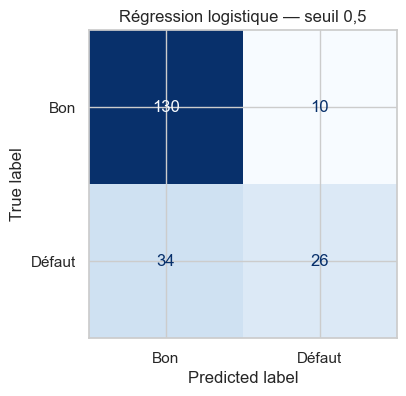

              precision    recall  f1-score   support

  Bon payeur      0.793     0.929     0.855       140
      Défaut      0.722     0.433     0.542        60

    accuracy                          0.780       200
   macro avg      0.757     0.681     0.698       200
weighted avg      0.772     0.780     0.761       200



In [29]:
proba_test = final_model.predict_proba(X_test)[:, 1]
pred_05 = (proba_test >= 0.5).astype(int)

fig, ax = plt.subplots(figsize=(4.5, 4))
ConfusionMatrixDisplay(confusion_matrix(y_test, pred_05), display_labels=["Bon", "Défaut"]).plot(
    ax=ax, cmap="Blues", colorbar=False)
ax.set_title(f"{retained_name} — seuil 0,5")
plt.show()
print(classification_report(y_test, pred_05, target_names=["Bon payeur", "Défaut"], digits=3))

**Rappel des définitions** (classe positive = *défaut*) :
- **Précision** = parmi les demandes signalées « défaut », combien le sont vraiment ? → coût des refus injustifiés.
- **Rappel** = parmi les vrais défauts, combien sont détectés ? → coût des pertes évitées.
- **F1** = moyenne harmonique des deux.

### 9.3 KS et courbe précision-rappel

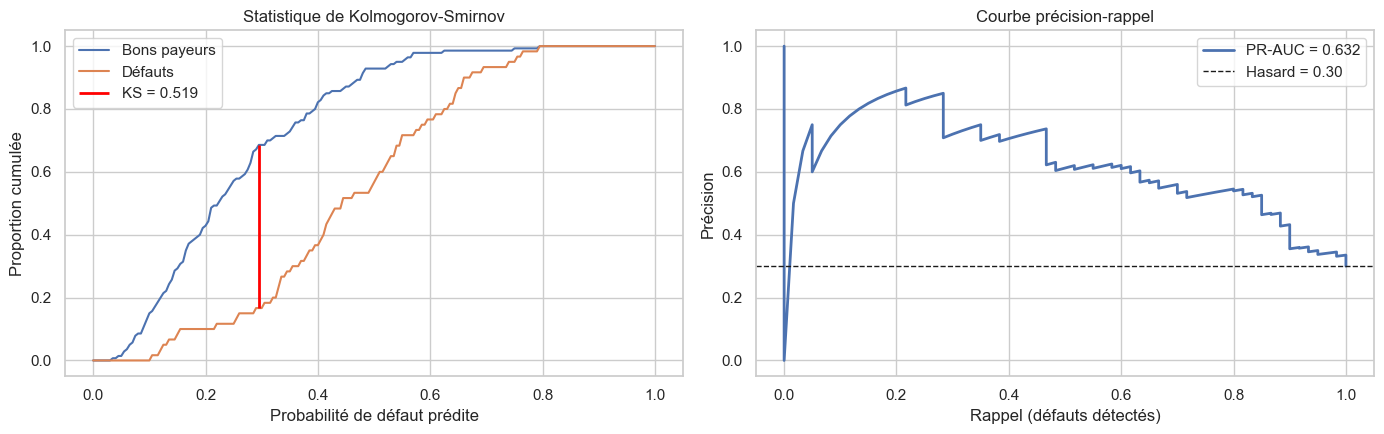

In [30]:
fig, axes = plt.subplots(1, 2, figsize=(14, 4.5))

# KS : écart maximal entre les distributions cumulées des scores des bons et des mauvais
grid = np.linspace(0, 1, 201)
cdf_bad = [(proba_test[y_test == 1] <= t).mean() for t in grid]
cdf_good = [(proba_test[y_test == 0] <= t).mean() for t in grid]
ks_idx = np.argmax(np.abs(np.array(cdf_good) - np.array(cdf_bad)))
axes[0].plot(grid, cdf_good, label="Bons payeurs")
axes[0].plot(grid, cdf_bad, label="Défauts")
axes[0].vlines(grid[ks_idx], cdf_bad[ks_idx], cdf_good[ks_idx], colors="red", lw=2,
               label=f"KS = {abs(cdf_good[ks_idx] - cdf_bad[ks_idx]):.3f}")
axes[0].set_xlabel("Probabilité de défaut prédite")
axes[0].set_ylabel("Proportion cumulée")
axes[0].set_title("Statistique de Kolmogorov-Smirnov")
axes[0].legend()

prec, rec, _ = precision_recall_curve(y_test, proba_test)
ap = average_precision_score(y_test, proba_test)
axes[1].plot(rec, prec, lw=2, label=f"PR-AUC = {ap:.3f}")
axes[1].axhline(y_test.mean(), color="k", ls="--", lw=1, label=f"Hasard = {y_test.mean():.2f}")
axes[1].set_xlabel("Rappel (défauts détectés)")
axes[1].set_ylabel("Précision")
axes[1].set_title("Courbe précision-rappel")
axes[1].legend()
plt.tight_layout()
plt.show()

### 9.4 Choisir le seuil de décision selon le **coût métier**

Le seuil 0,5 n'a **rien de naturel**. On cherche le seuil qui minimise le coût total : $\text{Coût} = 5 \times FN + 1 \times FP$.

⚠️ Le seuil est choisi sur les **prédictions hors-pli du train** (`cross_val_predict`), puis appliqué au test : choisir le seuil sur le test serait une nouvelle fuite de données.

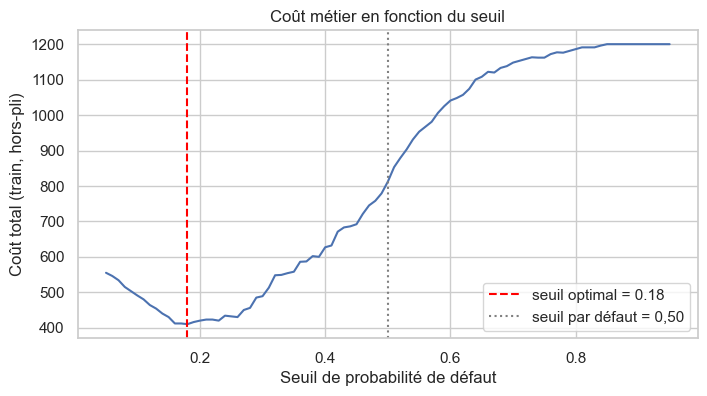

In [31]:
COST_FN, COST_FP = 5, 1
oof_proba = cross_val_predict(final_model, X_train, y_train, cv=cv, method="predict_proba")[:, 1]

thresholds = np.linspace(0.05, 0.95, 91)
def business_cost(y_true, proba, t):
    pred = (proba >= t).astype(int)
    fn = ((pred == 0) & (y_true == 1)).sum()
    fp = ((pred == 1) & (y_true == 0)).sum()
    return COST_FN * fn + COST_FP * fp

costs = [business_cost(y_train.values, oof_proba, t) for t in thresholds]
best_threshold = thresholds[int(np.argmin(costs))]

plt.figure(figsize=(8, 4))
plt.plot(thresholds, costs)
plt.axvline(best_threshold, color="red", ls="--", label=f"seuil optimal = {best_threshold:.2f}")
plt.axvline(0.5, color="grey", ls=":", label="seuil par défaut = 0,50")
plt.xlabel("Seuil de probabilité de défaut")
plt.ylabel("Coût total (train, hors-pli)")
plt.title("Coût métier en fonction du seuil")
plt.legend()
plt.show()

In [32]:
pred_opt = (proba_test >= best_threshold).astype(int)
summary = []
for label, pred in [("Seuil 0,50", pred_05), (f"Seuil optimal {best_threshold:.2f}", pred_opt)]:
    tn, fp, fn, tp = confusion_matrix(y_test, pred).ravel()
    summary.append({"Règle": label, "Défauts détectés (TP)": tp, "Défauts acceptés (FN)": fn,
                    "Bons refusés (FP)": fp, "Taux d'acceptation": (pred == 0).mean(),
                    "Rappel défaut": tp / (tp + fn), "Coût total": COST_FN * fn + COST_FP * fp})
pd.DataFrame(summary).set_index("Règle")

,Défauts détectés (TP),Défauts acceptés (FN),Bons refusés (FP),Taux d'acceptation,Rappel défaut,Coût total
Règle,,,,,,
"Seuil 0,50",26,34,10,0.820,0.433,180
Seuil optimal 0.18,54,6,86,0.300,0.900,116


> **Lecture :**
> - Avec une matrice de coût 5:1, le seuil optimal est **bas** — cohérent avec la théorie : pour des probabilités bien calibrées, le seuil optimal vaut $\frac{C_{FP}}{C_{FP}+C_{FN}} = \frac{1}{6} \approx 0{,}17$.
> - On détecte beaucoup plus de défauts et le coût total baisse nettement… mais le **taux d'acceptation s'effondre**, ce qui serait commercialement **inacceptable** pour la plupart des banques.
> - En pratique, on optimise le coût **sous contrainte** (taux d'acceptation minimal, objectifs de production), et une **zone grise** est envoyée en étude manuelle. C'est **une décision métier** (appétit pour le risque, stratégie commerciale), que le data scientist **éclaire** mais ne prend pas seul — l'application de scoring permet de jouer avec ce seuil.

### 9.5 De la probabilité à la grille de risque (classes A → E)

En pratique, la PD est traduite en **classes de risque**, plus faciles à utiliser par les équipes crédit et pour piloter le portefeuille. Les bornes sont fixées sur le train (quintiles de PD), puis appliquées au test : une bonne grille doit être **monotone** (le taux de défaut croît de A à E). Avec ~40 demandes par classe, de petites inversions entre classes voisines sont possibles et relèvent du bruit d'échantillonnage.

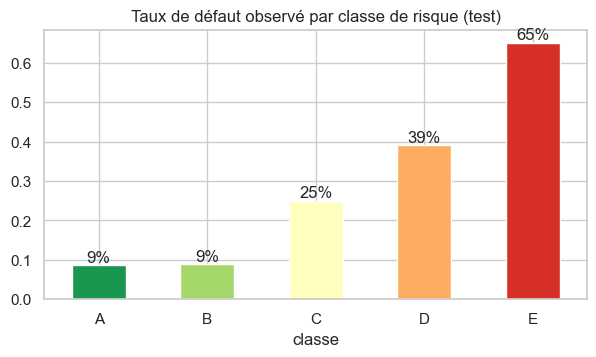

,Nb demandes,Taux de défaut observé,PD min,PD max
classe,,,,
A,35,0.086,0.000,0.132
B,45,0.089,0.132,0.230
C,36,0.250,0.230,0.336
D,41,0.390,0.336,0.473
E,43,0.651,0.473,1.000


In [33]:
_, bins = pd.qcut(oof_proba, q=5, retbins=True)
bins[0], bins[-1] = 0.0, 1.0
risk_classes = ["A", "B", "C", "D", "E"]

grid_test = pd.DataFrame({"classe": pd.cut(proba_test, bins=bins, labels=risk_classes, include_lowest=True),
                          "default": y_test.values})
risk_table = grid_test.groupby("classe", observed=False)["default"].agg(["size", "mean"]).rename(
    columns={"size": "Nb demandes", "mean": "Taux de défaut observé"})
risk_table["PD min"] = bins[:-1]
risk_table["PD max"] = bins[1:]

ax = risk_table["Taux de défaut observé"].plot.bar(figsize=(7, 3.5), color=plt.cm.RdYlGn_r(np.linspace(0.1, 0.9, 5)), rot=0)
ax.bar_label(ax.containers[0], fmt="{:.0%}")
ax.set_title("Taux de défaut observé par classe de risque (test)")
plt.show()
risk_table

### 9.6 Interpréter le modèle : *odds ratios* de la régression logistique

Pour une variable standardisée, **odds ratio = exp(coefficient)** : de combien la cote du défaut est multipliée quand la variable augmente d'un écart-type (ou quand la modalité est présente). > 1 : augmente le risque ; < 1 : le diminue.

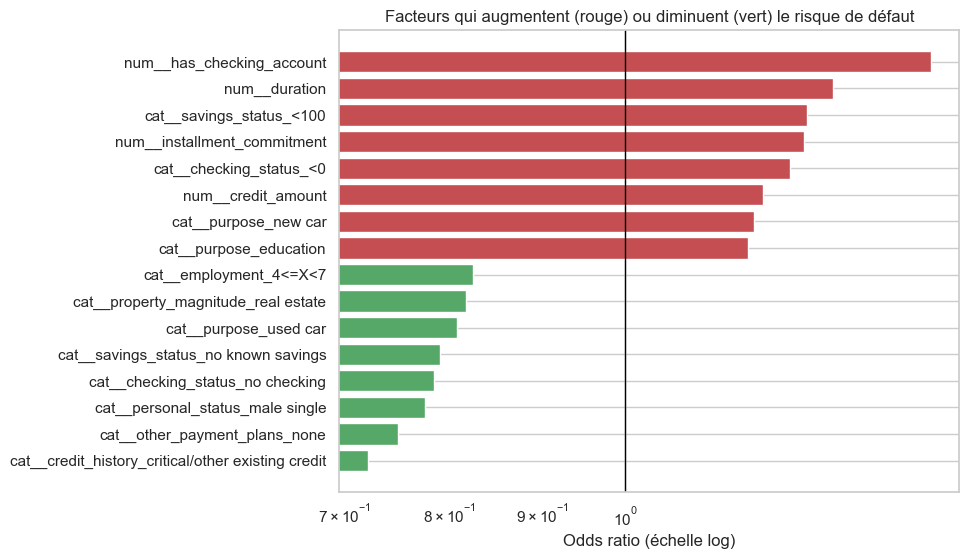

In [34]:
lr_final = tuned["Régression logistique"].best_estimator_
coefs = pd.Series(lr_final["model"].coef_[0], index=lr_final["pre"].get_feature_names_out())
coefs = coefs[coefs != 0]
top = pd.concat([coefs.sort_values().head(8), coefs.sort_values().tail(8)])
odds = np.exp(top)

plt.figure(figsize=(8, 6))
plt.barh(odds.index, odds.values, color=np.where(odds > 1, "#C44E52", "#55A868"))
plt.axvline(1, color="black", lw=1)
plt.xscale("log")
plt.xlabel("Odds ratio (échelle log)")
plt.title("Facteurs qui augmentent (rouge) ou diminuent (vert) le risque de défaut")
plt.show()

**Lecture :**
- Augmentent le risque : compte courant **débiteur** (`<0`) ou simplement **détenu** (`has_checking_account`), **durée** et **montant** élevés, **épargne faible** (`<100`), taux d'effort élevé, crédit pour une **voiture neuve** ou des **études**.
- Diminuent le risque : **pas de compte courant** dans la banque, **bien immobilier**, **voiture d'occasion**, pas d'autres crédits en cours, historique « critique » (crédits remboursés ailleurs — cf. EDA).
- Les odds ratios restent proches de 1 car le modèle est **fortement régularisé** (`C = 0,03`) : les coefficients sont « rétrécis » vers 0, ce qui le rend plus **stable**.
- ⚠️ `personal_status = male single` apparaît comme protecteur : le modèle utilise une **variable sensible** (sexe). C'est l'objet de la section suivante.

Ces résultats sont **cohérents avec l'EDA** et avec l'intuition métier : c'est une condition de la validation du modèle.

---
## 10. Équité & explicabilité

Le credit scoring est classé **« à haut risque »** par l'**AI Act** européen : exigences de gouvernance des données, de documentation, de **transparence**, de supervision humaine et de **non-discrimination**. Le RGPD (art. 22) encadre les décisions entièrement automatisées.

Le jeu contient deux variables sensibles : le **sexe** (dans `personal_status`) et le statut de **travailleur étranger**. Vérifions comment le modèle se comporte selon ces groupes.

In [35]:
eval_df = X_test.assign(default=y_test.values, proba=proba_test, refused=pred_opt,
                        sex=X_test["personal_status"].str.split().str[0])

def group_metrics(g):
    return pd.Series({"Nb": len(g), "Taux de défaut réel": g["default"].mean(),
                      "PD moyenne prédite": g["proba"].mean(), "Taux de refus": g["refused"].mean(),
                      "AUC": roc_auc_score(g["default"], g["proba"]) if g["default"].nunique() > 1 else np.nan})

display(eval_df.groupby("sex").apply(group_metrics))
display(eval_df.groupby("foreign_worker").apply(group_metrics))

,Nb,Taux de défaut réel,PD moyenne prédite,Taux de refus,AUC
sex,,,,,
female,61.000,0.328,0.355,0.754,0.827
male,139.000,0.288,0.297,0.676,0.790


,Nb,Taux de défaut réel,PD moyenne prédite,Taux de refus,AUC
foreign_worker,,,,,
no,6.000,0.167,0.289,0.667,1.000
yes,194.000,0.304,0.316,0.701,0.794


In [36]:
# « Fairness through unawareness » : que se passe-t-il si l'on retire les variables sensibles ?
X_train_fair = X_train.drop(columns=["personal_status", "foreign_worker"])
from sklearn.base import clone
fair_pipe = make_pipeline(clone(tuned["Régression logistique"].best_estimator_["model"]))
auc_fair = cross_val_score(fair_pipe, X_train_fair, y_train, cv=cv, scoring="roc_auc").mean()
print(f"AUC CV avec variables sensibles : {tuned['Régression logistique'].best_score_:.3f}")
print(f"AUC CV sans variables sensibles : {auc_fair:.3f}")

AUC CV avec variables sensibles : 0.779
AUC CV sans variables sensibles : 0.772


**À retenir :**
- Retirer les variables sensibles coûte **peu ou pas** de performance : c'est la pratique recommandée.
- Mais ce n'est **pas suffisant** : d'autres variables peuvent servir de **proxy** (ex. âge, type d'emploi, logement). Il faut **mesurer** les écarts de taux de refus et de performance entre groupes, et les **justifier**.
- Les effectifs sont ici faibles (200 demandes, dont **seulement 6 non-étrangers**) : les écarts doivent être lus avec prudence ; en production, ces indicateurs sont suivis sur des volumes bien plus grands.
- Pour expliquer **une décision individuelle**, on utilise les contributions des variables (coefficients × valeurs pour la régression logistique, **SHAP** pour les modèles d'arbres) — c'est ce que fait l'application de scoring.

---
## 11. Vers la production

### 11.1 Exporter le pipeline complet

On sérialise **le pipeline entier** (feature engineering + préprocessing + modèle) : en production, on lui donne les **données brutes** d'une demande, exactement comme dans le notebook. On sauvegarde aussi le **seuil** et la **grille de risque** : ils font partie du modèle.

In [37]:
import json
import os
import joblib

os.makedirs("models", exist_ok=True)
joblib.dump(final_model, "models/credit_scoring_pipeline.joblib")
with open("models/credit_scoring_config.json", "w") as f:
    json.dump({"model": retained_name, "threshold": float(best_threshold), "review_factor": 0.75,
               "risk_bins": [float(b) for b in bins], "risk_classes": risk_classes,
               "test_auc": float(roc_auc_score(y_test, proba_test))}, f, indent=2)
print(os.listdir("models"))

['credit_scoring_config.json', 'credit_scoring_pipeline.joblib']


In [38]:
REVIEW_FACTOR = 0.75   # zone grise = [75 % du seuil ; seuil[

def predict_applicant(applicant: dict) -> dict:
    # Score une demande de crédit brute (dictionnaire) avec le pipeline exporté.
    proba = float(final_model.predict_proba(pd.DataFrame([applicant]))[0, 1])
    risk_class = risk_classes[int(np.searchsorted(bins[1:-1], proba, side="right"))]
    if proba >= best_threshold:
        decision = "Refuser"
    elif proba >= REVIEW_FACTOR * best_threshold:
        decision = "Revoir"          # zone grise : étude manuelle par un analyste crédit
    else:
        decision = "Accepter"
    return {"probabilite_defaut": round(proba, 3), "classe_risque": risk_class, "decision": decision}

example = X_test.iloc[0].to_dict()
print(example)
predict_applicant(example)

{'checking_status': '0<=X<200', 'duration': 18, 'credit_history': 'existing paid', 'purpose': 'business', 'credit_amount': 1913, 'savings_status': '>=1000', 'employment': '<1', 'installment_commitment': 3, 'personal_status': 'male mar/wid', 'other_parties': 'none', 'residence_since': 3, 'property_magnitude': 'real estate', 'age': 36, 'other_payment_plans': 'bank', 'housing': 'own', 'existing_credits': 1, 'job': 'skilled', 'num_dependents': 1, 'own_telephone': 'yes', 'foreign_worker': 'yes'}


{'probabilite_defaut': 0.355, 'classe_risque': 'D', 'decision': 'Refuser'}

### 11.2 Exposer le modèle via une API (FastAPI)

Esquisse de l'endpoint (l'implémentation complète se trouve dans `apps/credit_scoring/backend/app.py`) :

```python
from fastapi import FastAPI
from pydantic import BaseModel
import joblib, pandas as pd

app = FastAPI(title="Credit Scoring API")
pipeline = joblib.load("credit_scoring_pipeline.joblib")

class Application(BaseModel):
    checking_status: str
    duration: int
    credit_amount: float
    # ... les 20 variables de la demande

@app.post("/predict")
def predict(app_in: Application):
    proba = pipeline.predict_proba(pd.DataFrame([app_in.model_dump()]))[0, 1]
    return {"probabilite_defaut": proba}
```

> **Architecture 3-tiers** : interface (Streamlit) → API (FastAPI) → modèle (pipeline sérialisé). L'API est le **contrat** entre le modèle et les applications métier.

### 11.3 Monitoring : détecter la dérive avec le PSI

Une fois en production, la population des demandeurs **évolue** (conjoncture, nouvelle offre commerciale, nouveau canal digital…). Le **Population Stability Index** compare la distribution actuelle à celle de référence (le train) :

$$PSI = \sum_{i} (\%_{actuel,i} - \%_{référence,i}) \times \ln\frac{\%_{actuel,i}}{\%_{référence,i}}$$

| PSI | Interprétation | Action |
|---|---|---|
| < 0,10 | Population stable | RAS |
| 0,10 – 0,25 | Dérive modérée | Analyser |
| > 0,25 | Dérive significative | Revoir / réentraîner le modèle |

On simule un lot « production » où une campagne marketing attire des clients **plus jeunes**, demandant des **montants plus élevés** sur des **durées plus longues**.

In [39]:
def psi(reference, current, bins=10):
    edges = np.unique(np.quantile(reference, np.linspace(0, 1, bins + 1)))
    edges[0], edges[-1] = -np.inf, np.inf
    ref = np.histogram(reference, edges)[0] / len(reference)
    cur = np.histogram(current, edges)[0] / len(current)
    ref, cur = np.clip(ref, 1e-4, None), np.clip(cur, 1e-4, None)
    return float(np.sum((cur - ref) * np.log(cur / ref)))

X_prod = X_test.copy()
X_prod["credit_amount"] = X_prod["credit_amount"] * 1.4
X_prod["duration"] = (X_prod["duration"] + 6).clip(upper=72)
X_prod["age"] = (X_prod["age"] - 5).clip(lower=19)

# Référence = scores hors-pli du train (un score calculé sur les données d'apprentissage serait biaisé)
ref_scores = oof_proba
psi_table = pd.DataFrame({
    "Variable": ["Score (PD)"] + num_cols,
    "PSI test (même période)": [psi(ref_scores, proba_test)] + [psi(X_train[c], X_test[c]) for c in num_cols],
    "PSI lot production simulé": [psi(ref_scores, final_model.predict_proba(X_prod)[:, 1])]
                                 + [psi(X_train[c], X_prod[c]) for c in num_cols],
}).set_index("Variable")

def flag(v):
    return "🟢 stable" if v < 0.1 else ("🟠 modérée" if v < 0.25 else "🔴 significative")
psi_table["Alerte production"] = psi_table["PSI lot production simulé"].apply(flag)
psi_table

,PSI test (même période),PSI lot production simulé,Alerte production
Variable,,,
Score (PD),0.022,0.130,🟠 modérée
duration,0.006,1.171,🔴 significative
credit_amount,0.040,0.398,🔴 significative
installment_commitment,0.014,0.014,🟢 stable
residence_since,0.014,0.014,🟢 stable
age,0.073,0.416,🔴 significative
existing_credits,0.003,0.003,🟢 stable
num_dependents,0.000,0.000,🟢 stable


> Le jeu de test (même période que le train) est **stable**, alors que le lot simulé déclenche des **alertes** sur `credit_amount`, `duration`, `age` et sur le **score lui-même**. En MLOps, ce calcul est **automatisé** (job quotidien/mensuel), relié à un **tableau de bord** et à des **alertes**, et peut déclencher un **réentraînement**.

---
## Synthèse

| Étape | Ce qu'il faut retenir |
|---|---|
| Cadrage | Définir la **métrique métier** (coût asymétrique) avant de modéliser |
| EDA | Comprendre les données, **confronter à l'expertise métier** |
| Preprocessing | Tout dans un **Pipeline** → pas de fuite de données, un seul objet à déployer |
| Feature engineering | Variables métier (mensualité, ratios) : souvent le meilleur levier |
| Modélisation | Comparer en **validation croisée** ; le plus complexe n'est pas toujours le meilleur |
| Sélection | Moins de variables pour une performance équivalente = modèle plus robuste et explicable |
| Overfitting | Diagnostiquer avec **courbes de validation / d'apprentissage** |
| Tuning | Grid / Random search en CV ; gains souvent modestes |
| Évaluation | AUC / **Gini** / KS, **seuil optimisé par le coût**, grille de risque monotone |
| Équité | Mesurer les écarts entre groupes, documenter (AI Act : haut risque) |
| Production | Pipeline sérialisé, API, **monitoring PSI** et réentraînement |

👉 **Suite :** lancer l'application `apps/credit_scoring` (API FastAPI + interface Streamlit avec dashboard de KPIs et monitoring).